# 10. Which way this right hand points

Run the cells from top to bottom. Select the `mano` kernel. The working directory may be `MANO` or `MANO/tutorial`.

The teaching figure in `learn_mano.py` draws the four fingers along +Y and the palm along +Z. That figure is only there so you can see the tree. The official template uses a different frame. Before you write an angle into `hand_pose`, use the axes of this template.

## Directions measured on the flat template

`flat_hand=True`, and every angle and every `beta` is 0. Run the next cell.

What you should see:

- The largest component of wrist-to-middle-MCP is X, and it is negative. The four fingers point along **-X**.
- The five fingertips spread along **Z**. The thumb is at **+Z**.
- Rotating only the index MCP by 30 degrees about **+Z** sends the tip toward **-Y**, so the palm is at **-Y**.


In [7]:
import sys
from pathlib import Path

import numpy as np

MANO = Path.cwd().resolve()
if not (MANO / "mano_skeleton.py").exists():
    MANO = MANO.parent
if str(MANO) not in sys.path:
    sys.path.insert(0, str(MANO))

%matplotlib inline
from official_mano import require_model

model = require_model()
flat = model.forward(flat_hand=True)
direction = flat["joints"][4] - flat["joints"][0]
print("wrist -> middle MCP (metres)", np.round(direction, 4))

for name in ("thumb", "index", "middle", "ring", "pinky"):
    tip = flat["tips"][name] * 1000
    print(f"{name:<6} tip mm  x={tip[0]:7.1f}  y={tip[1]:7.1f}  z={tip[2]:7.1f}")

print(
    "joint 15 to thumb tip, mm",
    round(float(np.linalg.norm(flat["joints"][15] - flat["tips"]["thumb"]) * 1000), 1),
)


wrist -> middle MCP (metres) [-0.0947 -0.0015 -0.0034]
thumb  tip mm  x=    3.7  y=  -16.4  z=   94.1
index  tip mm  x=  -72.7  y=    5.1  z=   28.5
middle tip mm  x=  -78.8  y=    9.4  z=  -10.8
ring   tip mm  x=  -62.3  y=    6.7  z=  -40.6
pinky  tip mm  x=  -23.1  y=   -2.6  z=  -70.2
joint 15 to thumb tip, mm 35.4


On the local axes of this official right hand:

| Positive rotation about | What happens to the four fingers |
|---|---|
| +Z | Flexion toward the palm (-Y) |
| +Y | Spread or close along Z. +Y on the index moves it toward the thumb side |
| +X | Twist along the finger. The tip barely moves |

The next cell rotates only the index MCP, 30 degrees at a time, and prints the tip displacement.


In [8]:
base = flat["tips"]["index"]
for axis, component in (("X", 0), ("Y", 1), ("Z", 2)):
    hand_pose = np.zeros(45)
    hand_pose[component] = np.deg2rad(30.0)
    out = model.forward(hand_pose=hand_pose, flat_hand=True)
    delta = (out["tips"]["index"] - base) * 1000
    print(f"MCP +30 deg {axis}   index tip mm {np.round(delta, 2)}   length {np.linalg.norm(delta):.1f}")


MCP +30 deg X   index tip mm [-0.   -1.32  1.73]   length 2.2
MCP +30 deg Y   index tip mm [11.56 -0.   39.94]   length 41.6
MCP +30 deg Z   index tip mm [  8.82 -40.68  -0.  ]   length 41.6


In [9]:
np.zeros(45)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

The thumb is oblique. Its bones carry both -X and +Z. The next cell rotates the thumb CMC, MCP, and IP by 30 degrees each. Do not copy the four-finger rule "flexion is rz" onto the thumb. For the motion you want, rotate one axis, read the tip displacement, and then choose the component.


In [10]:
base = flat["tips"]["thumb"]
for joint_name, start in (("CMC", 36), ("MCP", 39), ("IP", 42)):
    for axis, component in (("X", 0), ("Y", 1), ("Z", 2)):
        hand_pose = np.zeros(45)
        hand_pose[start + component] = np.deg2rad(30.0)
        out = model.forward(hand_pose=hand_pose, flat_hand=True)
        delta = (out["tips"]["thumb"] - base) * 1000
        print(f"{joint_name} +30 deg {axis}  thumb tip mm {np.round(delta, 1)}  length {np.linalg.norm(delta):.1f}")
    print("---")


CMC +30 deg X  thumb tip mm [ -0.  -30.1 -11.9]  length 32.4
CMC +30 deg Y  thumb tip mm [40.1 -0.  25.6]  length 47.6
CMC +30 deg Z  thumb tip mm [ 12.7 -33.   -0. ]  length 35.3
---
MCP +30 deg X  thumb tip mm [  0.  -18.1  -9.2]  length 20.3
MCP +30 deg Y  thumb tip mm [25.6 -0.  19. ]  length 31.9
MCP +30 deg Z  thumb tip mm [ 10.5 -23.1   0. ]  length 25.4
---
IP +30 deg X  thumb tip mm [ -0.3 -11.5  -4.3]  length 12.3
IP +30 deg Y  thumb tip mm [15.9  0.9 10.5]  length 19.1
IP +30 deg Z  thumb tip mm [  5.3 -12.   -1.1]  length 13.1
---


## Flex only the index finger

The three index joints are the first 9 numbers of `hand_pose`. The Z component of each joint is the last of the three: `hand_pose[2]`, `[5]`, and `[8]`. The next cell sets MCP, PIP, and DIP to 40°, 65°, and 45°, and compares that with the same angles about X. The figure looks from the palm side. Red points are fingertips.


about Z, index tip moved mm 52.8
about X, index tip moved mm 1.2
about Z, middle tip moved mm 0.002
about Z, ring tip moved mm 0.001
about Z, pinky tip moved mm 0.001
about Z, thumb tip moved mm 0.006
index MCP/PIP/DIP moved mm [ 0.    5.74 25.51]


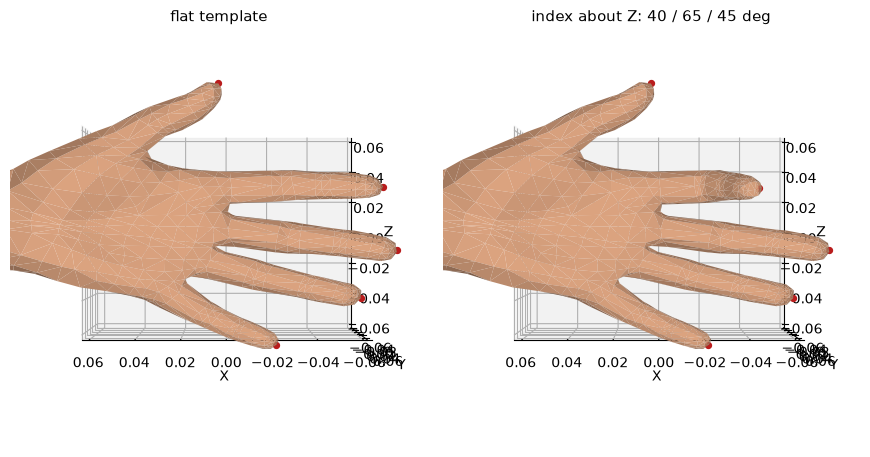

In [18]:
def show_hands(panels, faces, titles):
    """View the mesh from the palm side (-Y). Red points are the five fingertips."""
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d.art3d import Poly3DCollection

    palm = np.array([0.0, -1.0, 0.0])
    cloud = np.vstack([item["vertices"] for item in panels])
    fig = plt.figure(figsize=(4.4 * len(panels), 4.6))
    for index, (title, result) in enumerate(zip(titles, panels), start=1):
        axis = fig.add_subplot(1, len(panels), index, projection="3d")
        triangles = result["vertices"][faces]
        normals = np.cross(triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0])
        normals /= np.maximum(np.linalg.norm(normals, axis=1, keepdims=True), 1e-12)
        facing = normals @ palm > 0.0
        shade = 0.55 + 0.45 * np.abs(normals[facing] @ palm)
        color = np.zeros((int(facing.sum()), 4))
        color[:, 0] = 0.86 * shade
        color[:, 1] = 0.64 * shade
        color[:, 2] = 0.50 * shade
        color[:, 3] = 1.0
        axis.add_collection3d(Poly3DCollection(triangles[facing], facecolors=color, linewidths=0))
        tips = np.stack([result["tips"][name] for name in ("thumb", "index", "middle", "ring", "pinky")])
        axis.scatter(tips[:, 0], tips[:, 1], tips[:, 2], s=18, c="#b91c1c", depthshade=False)
        axis.set_title(title, fontsize=11)
        axis.view_init(elev=0, azim=90)
        axis.set_xlabel("X")
        axis.set_ylabel("Y")
        axis.set_zlabel("Z")
        center = cloud.mean(axis=0)
        radius = 0.55 * np.max(np.linalg.norm(cloud - center, axis=1))
        axis.set_xlim(center[0] - radius, center[0] + radius)
        axis.set_ylim(center[1] - radius, center[1] + radius)
        axis.set_zlim(center[2] - radius, center[2] + radius)
    fig.tight_layout()
    plt.show()

hand_pose = np.zeros(45)
hand_pose[2], hand_pose[5], hand_pose[8] = np.deg2rad([10.0, 45.0, 10.0])
curl = model.forward(hand_pose=hand_pose, flat_hand=True)

twist_pose = np.zeros(45)
twist_pose[0], twist_pose[3], twist_pose[6] = np.deg2rad([10.0, 45.0, 10.0])
twist = model.forward(hand_pose=twist_pose, flat_hand=True)

print("about Z, index tip moved mm", round(float(np.linalg.norm(curl["tips"]["index"] - flat["tips"]["index"]) * 1000), 1))
print("about X, index tip moved mm", round(float(np.linalg.norm(twist["tips"]["index"] - flat["tips"]["index"]) * 1000), 1))
for name in ("middle", "ring", "pinky", "thumb"):
    move = np.linalg.norm(curl["tips"][name] - flat["tips"][name]) * 1000
    print(f"about Z, {name} tip moved mm {move:.3f}")

index_joint_move = np.linalg.norm(curl["joints"][1:4] - flat["joints"][1:4], axis=1) * 1000
print("index MCP/PIP/DIP moved mm", np.round(index_joint_move, 2))

show_hands(
    [flat, curl],
    model.faces,
    ["flat template", "index about Z: 40 / 65 / 45 deg"],
)


About Z, the index tip moves about 98 mm, and the other four fingertips barely move. The index MCP itself stays put. The PIP moves about 23 mm and the DIP about 54 mm. The same angles about X move the index tip by about 4 mm.

## Check

To flex this right hand's index finger toward the palm, increase `hand_pose[2]`, `[5]`, and `[8]`. The numbers are radians.

The next chapter handles the default that is easiest to get wrong: which hand "all zeros" actually is.
